In [3]:
#Get the building data for the study area using LINZ service.

import geopandas as gpd
import rasterio

SIMULATION_DATA_DIR = f"/data/westport/data"

BUILDING_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/buildings.gpkg"

DEM_FILE_PATH = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/Topo.tif"
LINZ_KEY = "a06a74b6c02f4d4a81f999bd09034897"

with rasterio.open(DEM_FILE_PATH) as dem_dataset:
    dem_bounds = dem_dataset.bounds
    dem_crs = dem_dataset.crs

print(f"DEM Bounds: {dem_bounds}")
print(f"DEM CRS: {dem_crs}")

#convert dem bounds to bbox coordinates to ESPG:4167 (NZGD2000)
# from pyproj import Transformer
# transformer = Transformer.from_crs(dem_crs, "EPSG:4167", always_xy=True)
# left, bottom = transformer.transform(dem_bounds.left, dem_bounds.bottom)
# right, top = transformer.transform(dem_bounds.right, dem_bounds.top)


bbox = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top}"

# Assumes dem_bounds is already in NZTM2000 (EPSG:2193)
bbox_str = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top},EPSG:2193"

wfs_url = (
    f"https://data.linz.govt.nz/services;key={LINZ_KEY}/wfs?"
    f"service=WFS&version=2.0.0&request=GetFeature"
    f"&typeNames=layer-101290"
    f"&bbox={bbox_str}"
    f"&outputFormat=application/json"
)

buildings = gpd.read_file(wfs_url)
print(f"Fetched {len(buildings)} buildings")

# Save the building data to a GeoJSON file
buildings.to_file(BUILDING_FILE_PATH, driver="gpkg")
print(f"Building data saved to {BUILDING_FILE_PATH}")

DEM Bounds: BoundingBox(left=1478882.0, bottom=5367810.8, right=1490478.8, top=5379561.2)
DEM CRS: PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]]
Fetched 6143 buildings
Building data saved to /data/westport/data/exposure/buildings.gpkg


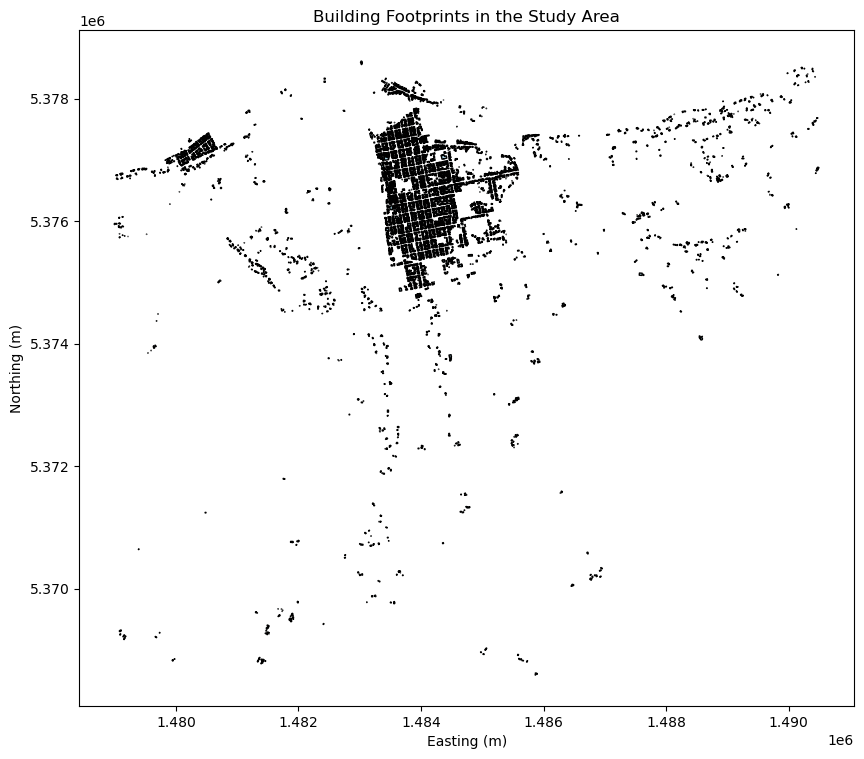

Min building area: 10.0 m²
Max building area: 7560.8 m²
Mean building area: 143.9 m²
Median building area: 114.7 m²


In [2]:
#plot the buildings
import matplotlib.pyplot as plt 
fig, ax = plt.subplots(figsize=(10, 10))
buildings.plot(ax=ax, color='lightblue', edgecolor='black')
ax.set_title("Building Footprints in the Study Area")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.show()


# Make sure you're in a projected CRS for accurate area in m²
buildings_projected = buildings.to_crs(epsg=2193)

print(f"Min building area: {buildings_projected.geometry.area.min():.1f} m²")
print(f"Max building area: {buildings_projected.geometry.area.max():.1f} m²")
print(f"Mean building area: {buildings_projected.geometry.area.mean():.1f} m²")
print(f"Median building area: {buildings_projected.geometry.area.median():.1f} m²")

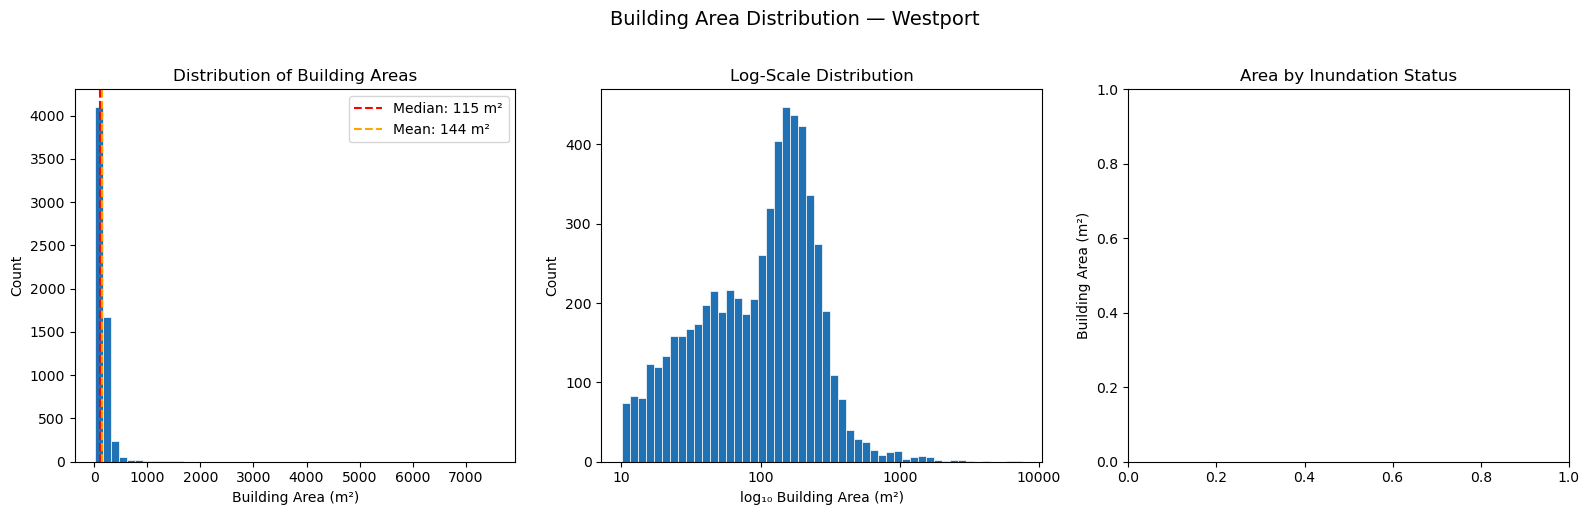

In [5]:
import matplotlib.pyplot as plt
import numpy as np

buildings_projected = buildings.to_crs(epsg=2193)
area = buildings_projected.geometry.area

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── 1. HISTOGRAM ──────────────────────────────────────────────────────────────
axes[0].hist(area, bins=50, color="#2171b5", edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Building Area (m²)")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of Building Areas")
axes[0].axvline(area.median(), color="red",    linestyle="--", label=f"Median: {area.median():.0f} m²")
axes[0].axvline(area.mean(),   color="orange", linestyle="--", label=f"Mean: {area.mean():.0f} m²")
axes[0].legend()

# ── 2. LOG-SCALE HISTOGRAM (handles skew better) ──────────────────────────────
axes[1].hist(np.log10(area), bins=50, color="#2171b5", edgecolor="white", linewidth=0.5)
axes[1].set_xlabel("log₁₀ Building Area (m²)")
axes[1].set_ylabel("Count")
axes[1].set_title("Log-Scale Distribution")
axes[1].set_xticks([1, 2, 3, 4])
axes[1].set_xticklabels(["10", "100", "1000", "10000"])

# ── 3. BOXPLOT BY INUNDATION STATUS ───────────────────────────────────────────
buildings_projected["area"]      = area

axes[2].set_ylabel("Building Area (m²)")
axes[2].set_title("Area by Inundation Status")

plt.suptitle("Building Area Distribution — Westport", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [9]:
!pip install rasterstats

2208.73s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [rasterstats]


In [13]:
# Overlay flood extent on the building footprints
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import contextily as ctx
from rasterstats import zonal_stats

# ── CONFIGURATION ─────────────────────────────────────────────────────────────

SIMULATION_DATA_DIR = f"/data/westport/data"
FLOOD_MAP_FILE_PATH = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/July_2021_surveyed_flood_depth.tif"
DEPTH_RASTER    = FLOOD_MAP_FILE_PATH
BUILDING_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/buildings.geojson"

DEPTH_THRESHOLD = 0.1   # m  — minimum depth to count as inundated

pythongrey_red = LinearSegmentedColormap.from_list(
    "grey_red", ["#000000", "#fc8d59", "#d7191c"]  # grey → orange → deep red
)

# ── LOAD BUILDINGS ────────────────────────────────────────────────────────────

buildings = gpd.read_file(BUILDING_FILE_PATH)
buildings = buildings[buildings.geometry.area >= 50].reset_index(drop=True)
print(f"Loaded {len(buildings)} buildings")

# ── REPROJECT BUILDINGS TO RASTER CRS ─────────────────────────────────────────

with rasterio.open(DEPTH_RASTER) as src:
    raster_crs = src.crs
    nodata     = src.nodata

buildings = buildings.to_crs(raster_crs)

# ── ZONAL STATS ───────────────────────────────────────────────────────────────

depth_stats = zonal_stats(buildings, DEPTH_RASTER,
                          stats=["max", "mean"], nodata=nodata, all_touched=False)
# vel_stats   = zonal_stats(buildings, VELOCITY_RASTER,
#                           stats=["max", "mean"], nodata=nodata, all_touched=False)

buildings["depth_max"]  = [s["max"]  or 0.0 for s in depth_stats]
buildings["depth_mean"] = [s["mean"] or 0.0 for s in depth_stats]
# buildings["vel_max"]    = [s["max"]  or 0.0 for s in vel_stats]
# buildings["dv_product"] = buildings["depth_max"] * buildings["vel_max"]
buildings["inundated"]  = buildings["depth_max"] >= DEPTH_THRESHOLD

print(f"Inundated buildings: {buildings['inundated'].sum()} "
      f"({buildings['inundated'].mean()*100:.1f}%)")



Loaded 4439 buildings
Inundated buildings: 1855 (41.8%)


In [ ]:
import folium
import json
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib import cm

import os
os.system(f"jupyter trust {os.path.abspath('your_notebook_name.ipynb')}")

# ── COLORMAP: grey → red ──────────────────────────────────────────────────────

grey_red = LinearSegmentedColormap.from_list("grey_red", ["#d3d3d3", "#fc8d59", "#d7191c"])

def depth_to_hex(depth):
    if depth < 0.1:
        return "#2ecc71"   # green
    elif depth < 0.3:
        return "#f1c40f"   # yellow
    else:
        return "#e74c3c"   # red

# ── REPROJECT TO WGS84 (folium requires lat/lon) ──────────────────────────────

buildings_wgs = buildings.to_crs(epsg=4326)

# ── CENTRE MAP ON INUNDATED BUILDINGS ─────────────────────────────────────────

inundated_wgs = buildings_wgs[buildings_wgs["inundated"]]
centre = inundated_wgs.dissolve().centroid.iloc[0]

m = folium.Map(
    location=[centre.y, centre.x],
    zoom_start=15,
    tiles="Esri.WorldImagery",  # satellite basemap
    attr="Esri"
)

# ── ADD BUILDINGS ─────────────────────────────────────────────────────────────

for _, row in buildings_wgs.iterrows():
    depth = row["depth_max"]
    colour = depth_to_hex(depth) if row["inundated"] else "#aaaaaa"

    folium.GeoJson(
        row["geometry"].__geo_interface__,
        style_function=lambda x, c=colour: {
            "fillColor": c,
            "color": "black",
            "weight": 0.5,
            "fillOpacity": 0.8
        },
        tooltip=folium.Tooltip(
            f"Depth: {depth:.2f} m<br>"
            f"Inundated: {row['inundated']}"
        )
    ).add_to(m)
    
# -- ADD INUNDATION MAP OVERLAY (OPTIONAL) ────────────────────────────────────────────────────────



# ── ADD LEGEND ────────────────────────────────────────────────────────────────

legend_html = """
<div style="position: fixed; bottom: 40px; left: 40px; z-index: 1000;
     background-color: white; padding: 12px; border-radius: 6px;
     border: 1px solid grey; font-size: 13px;">
  <b>Max Flood Depth (m)</b><br>
  <i style="background:#2ecc71;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> &lt; 0.1 m (shallow)<br>
  <i style="background:#f1c40f;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> 0.1 – 0.3 m (moderate)<br>
  <i style="background:#e74c3c;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> &gt; 0.3 m (deep)<br>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

# ── DISPLAY ───────────────────────────────────────────────────────────────────

m.save("flood_map.html")

from IPython.display import IFrame
# IFrame("flood_map.html", width="100%", height=600)

DEM Bounds: BoundingBox(left=1478882.0, bottom=5367810.8, right=1490478.8, top=5379561.2)
DEM CRS: PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]]
Study Area Bounds (transformed): [19095898.39747464 -5136149.29453732 19111682.36085452 -5120103.06572846]


AttributeError: 'dict' object has no attribute 'build_url'

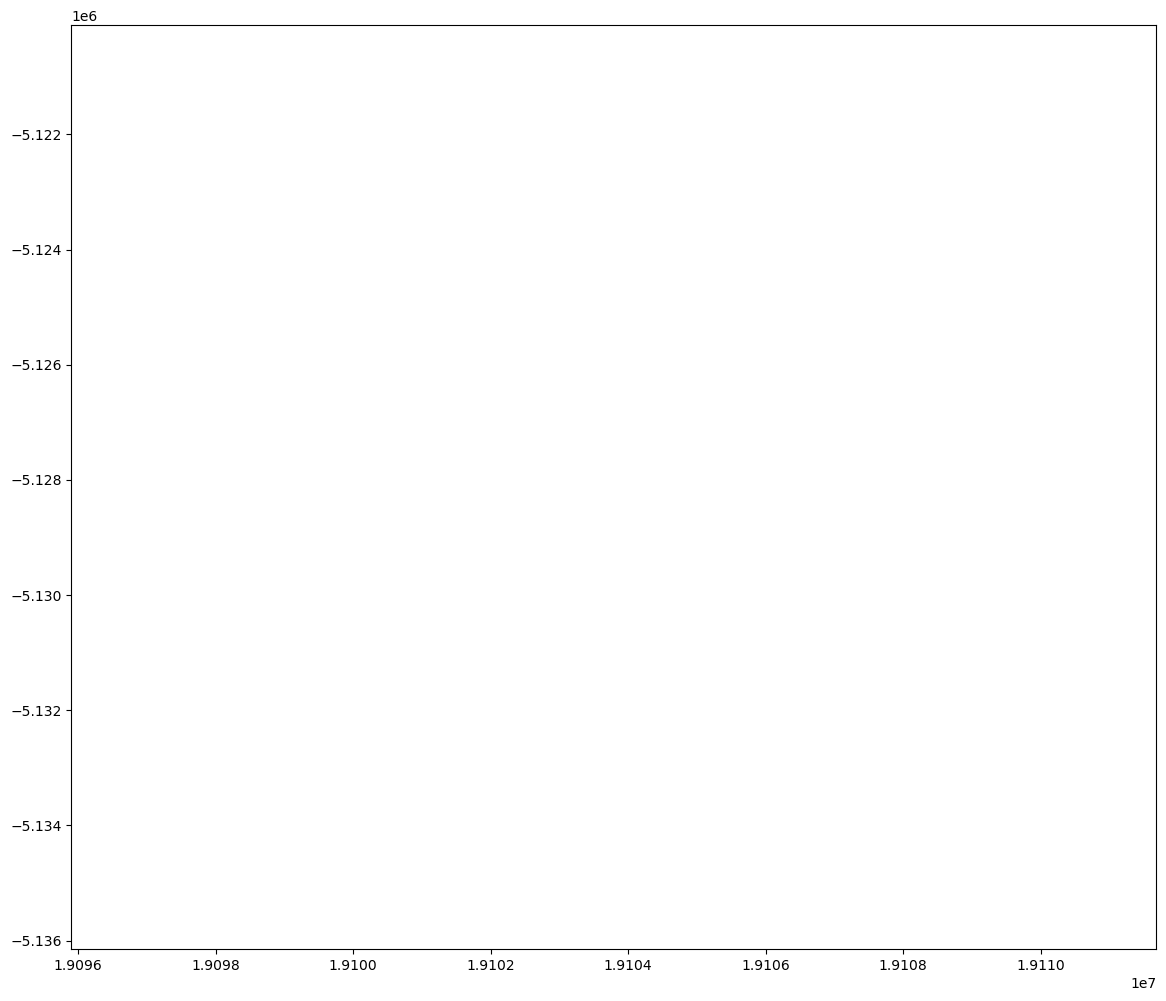

In [14]:
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt
import contextily as ctx
import rasterio

SIMULATION_DATA_DIR = f"/data/westport/data"

DEM_FILE_PATH = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/Topo.tif"

# Open the DEM file to get coordinate bounds
with rasterio.open(DEM_FILE_PATH) as dem_dataset:
    # Get bounds of the DEM data directly from dataset
    dem_bounds = dem_dataset.bounds
    dem_crs = dem_dataset.crs
    
print(f"DEM Bounds: {dem_bounds}")
print(f"DEM CRS: {dem_crs}")

# Create a bounding box from the DEM bounds (left, bottom, right, top)
study_area_box = box(dem_bounds.left, dem_bounds.bottom, dem_bounds.right, dem_bounds.top)
study_area_gdf = gpd.GeoDataFrame([1], geometry=[study_area_box], crs=dem_crs)

# Only reproject if CRS is not Web Mercator
if dem_crs and dem_crs.to_string() != "EPSG:3857":
    study_area_gdf_web = study_area_gdf.to_crs(epsg=3857)
else:
    study_area_gdf_web = study_area_gdf.copy()

print(f"Study Area Bounds (transformed): {study_area_gdf_web.bounds.values[0]}")

# Create figure with satellite basemap
fig, ax = plt.subplots(figsize=(14, 12))

# Set axis limits to the study area before adding basemap
bounds_row = study_area_gdf_web.bounds.iloc[0]
ax.set_xlim(bounds_row['minx'], bounds_row['maxx'])
ax.set_ylim(bounds_row['miny'], bounds_row['maxy'])

# Get the base map for the study area using LINZ service
koordinates = {
    "url": "https://data.linz.govt.nz/services/query/v1/vector.json?key=a06a74b6c02f4d4a81f999bd09034897&layer=101292&x=[x]&y=[y]&max_results=3&radius=10000&geometry=true&with_field_names=true",
    "attribution": "© Koordinates / LINZ"
}

ctx.add_basemap(ax, source=koordinates, crs=study_area_gdf_web.crs.to_string(), zoom=12)
# Plot the study area boundary on top of the basemap
study_area_gdf_web.boundary.plot(ax=ax, edgecolor='red', linewidth=2)
ax.set_title("Study Area with LINZ Basemap", fontsize=16)
ax.set_axis_off()
plt.show()

In [2]:
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap, Normalize
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
import numpy as np
import matplotlib.pyplot as plt
import folium
from folium import raster_layers
from IPython.display import IFrame
import base64
from io import BytesIO

# ── CONFIGURATION ─────────────────────────────────────────────────────────────

SIMULATION_DATA_DIR  = "/data/westport/data"
DEPTH_RASTER         = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/July_2021_surveyed_flood_depth.tif"
BUILDING_FILE_PATH   = f"{SIMULATION_DATA_DIR}/exposure/buildings.geojson"
DEPTH_THRESHOLD      = 0.1

# ── LOAD & PROCESS BUILDINGS (your existing code) ─────────────────────────────

buildings = gpd.read_file(BUILDING_FILE_PATH)
buildings = buildings[buildings.geometry.area >= 50].reset_index(drop=True)

with rasterio.open(DEPTH_RASTER) as src:
    raster_crs = src.crs
    nodata     = src.nodata
    

buildings = buildings.to_crs(raster_crs)

from rasterstats import zonal_stats
depth_stats = zonal_stats(buildings, DEPTH_RASTER,
                          stats=["max", "mean"], nodata=nodata, all_touched=False)
buildings["depth_max"]  = [s["max"]  or 0.0 for s in depth_stats]
buildings["depth_mean"] = [s["mean"] or 0.0 for s in depth_stats]
buildings["inundated"]  = buildings["depth_max"] >= DEPTH_THRESHOLD

print(f"Inundated buildings: {buildings['inundated'].sum()} "
      f"({buildings['inundated'].mean()*100:.1f}%)")



# ── REPROJECT RASTER TO WGS84 FOR FOLIUM ──────────────────────────────────────

def raster_to_wgs84_array(raster_path, nodata_val):
    with rasterio.open(raster_path) as src:
        transform, width, height = calculate_default_transform(
            src.crs, "EPSG:4326", src.width, src.height, *src.bounds
        )
        data = np.zeros((height, width), dtype=np.float32)
        reproject(
            source=rasterio.band(src, 1),
            destination=data,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs="EPSG:4326",
            resampling=Resampling.bilinear
        )

        # Get WGS84 bounds [south, west, north, east]
        from rasterio.transform import array_bounds
        west, south, east, north = rasterio.transform.array_bounds(height, width, transform)

    # Fix 1: Replace nodata and nan with 0
    if nodata_val is not None:
        data[data == nodata_val] = 0.0
    data = np.nan_to_num(data, nan=0.0)

    # Mask dry areas
    mask = data <= DEPTH_THRESHOLD

    # Fix 2: Clip data to valid range before normalising to avoid overflow
    valid_data = data[~mask]
    if len(valid_data) == 0:
        print("WARNING: No flooded pixels found in raster")
        return None, None

    vmax = float(np.percentile(valid_data, 95))
    data_clipped = np.clip(data, DEPTH_THRESHOLD, vmax)

    blue = LinearSegmentedColormap.from_list(
    "blue_flood", ["#deebf7", "#9ecae1", "#2171b5", "#08306b"]  # very light → deep navy
    )       
    norm = Normalize(vmin=DEPTH_THRESHOLD, vmax=vmax)
    rgba = blue(norm(data_clipped), bytes=True)
    rgba[mask, 3] = 0   # transparent where dry

    # Fix 3: Correct bounds order for folium [[south, west], [north, east]]
    bounds = [[south, west], [north, east]]
    print(f"Raster WGS84 bounds: S={south:.4f}, W={west:.4f}, N={north:.4f}, E={east:.4f}")

    return rgba, bounds

rgba_array, raster_bounds = raster_to_wgs84_array(DEPTH_RASTER, nodata)


# Convert RGBA array to base64 PNG for folium ImageOverlay
buf = BytesIO()
plt.imsave(buf, rgba_array, format="png")
buf.seek(0)
img_b64 = base64.b64encode(buf.read()).decode("utf-8")
img_url = f"data:image/png;base64,{img_b64}"

# ── BUILD FOLIUM MAP ───────────────────────────────────────────────────────────

buildings_wgs = buildings.to_crs(epsg=4326)
inundated_wgs = buildings_wgs[buildings_wgs["inundated"]]

centre = (inundated_wgs.to_crs(epsg=2193)
                       .dissolve()
                       .centroid
                       .to_crs(epsg=4326)
                       .iloc[0])

keep_cols = ["geometry", "depth_max", "depth_mean", "inundated"]
buildings_wgs = buildings.to_crs(epsg=4326)[keep_cols]


m = folium.Map(
    location=[centre.y, centre.x],
    zoom_start=15,
    tiles="Esri.WorldImagery",
    attr="Esri"
)

# ── LAYER 1: FLOOD RASTER ─────────────────────────────────────────────────────

folium.raster_layers.ImageOverlay(
    image=img_url,
    bounds=[[-41.8334, 171.5518], [-41.7296, 171.6724]],  # hardcode from your print output
    opacity=0.8,
    name="Flood Depth Raster",
    interactive=False,
    cross_origin=False, 
    z_index=1
).add_to(m)


# ── LAYER 3: JUST BUILDINGS  ────────────────────────────────────────────────────────

folium.GeoJson(
    buildings_wgs.__geo_interface__,
    name="Buildings",
    style_function=lambda x: {
        "fillColor": "#cccccc",
        "color":     "black",
        "weight":    0.8,
        "fillOpacity": 0.2
    },
    # tooltip=folium.GeoJsonTooltip(
    #     fields=["area"],
    #     aliases=["Area (m²)"]
    # )
).add_to(m)


# ── LAYER 3: BUILDINGS EXPOSURE ────────────────────────────────────────────────────────

def depth_to_hex(depth):
    if depth < 0.1:
        return "#2ecc71"
    elif depth < 0.3:
        return "#f1c40f"
    else:
        return "#e74c3c"

folium.GeoJson(
    buildings_wgs.__geo_interface__,
    name="Buildings Exposure",
    style_function=lambda x: {
        "fillColor": depth_to_hex(x["properties"]["depth_max"]),
        "color":     "black",
        "weight":    0.8,
        "fillOpacity": 0.9 if x["properties"]["inundated"] else 0.2
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["depth_max", "depth_mean", "inundated"],
        aliases=["Max Depth (m)", "Mean Depth (m)", "Inundated"]
    )
).add_to(m)

# ___ LAYER 4: PLACRD DATA ────────────────────────────────────────────────────────
#Placard data
import geopandas as gpd
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"

#Visualise the placard data
placards = gpd.read_file(PLACRD_FILE_PATH)
placards = placards.to_crs(epsg=4326)

def placard_color(color_val):
    color_map = {
        "Red":   "#e74c3c",
        "Green": "#2ecc71",
        "1":     "#f1c40f",   # MBIE records with no colour — assign yellow
    }
    return color_map.get(str(color_val), "#aaaaaa")  # grey as fallback

placard_layer = folium.FeatureGroup(name="Placards")

folium.GeoJson(
    placards.__geo_interface__,
    style_function=lambda x: {
        "fillColor":   placard_color(x["properties"]["color"]),
        "color":       "black",
        "weight":      1,
        "fillOpacity": 0.8
    },
    tooltip=folium.GeoJsonTooltip(
        fields=  ["damage",    "color",  "source", "DamageNb"],
        aliases= ["Damage",    "Color",  "Source", "Damage Level"]
    )
).add_to(placard_layer)


placard_layer.add_to(m)


# ── LAYER CONTROL + LEGEND ────────────────────────────────────────────────────

folium.LayerControl().add_to(m)

legend_html = """
<div style="position: fixed; bottom: 40px; left: 40px; z-index: 1000;
     background-color: white; padding: 12px; border-radius: 6px;
     border: 1px solid grey; font-size: 13px;">
  <b>Max Flood Depth (m)</b><br>
  <i style="background:#2ecc71;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> &lt; 0.1 m<br>
  <i style="background:#f1c40f;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> 0.1 – 0.3 m<br>
  <i style="background:#e74c3c;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> &gt; 0.3 m<br>
  <hr style="margin:6px 0">
  <b>Flood Raster</b><br>
  <b>Flood Depth Raster</b><br>
  <i style="background:#deebf7;width:14px;height:14px;display:inline-block;margin-right:6px;border:1px solid #ccc;"></i> Shallow (0.1 m)<br>
  <i style="background:#9ecae1;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> Moderate (0.5 m)<br>
  <i style="background:#2171b5;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> Deep (1.0 m)<br>
  <i style="background:#08306b;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> Very deep (&gt; 2.0 m)<br>
  <hr style="margin:6px 0">
  <b>Placards</b><br>
  <i style="background:#9b59b6;width:14px;height:14px;display:inline-block;
     margin-right:6px;border-radius:50%;"></i> Placard location<br>
  
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))


# opacity_slider = """
# <div style="position: fixed; top: 40px; right: 40px; z-index: 1000;
#      background-color: white; padding: 10px; border-radius: 6px;
#      border: 1px solid grey; font-size: 13px;">
#   <b>Flood Raster Opacity</b><br>
#   <input type="range" min="0" max="1" step="0.1" value="0.6"
#      oninput="document.querySelectorAll('.leaflet-image-layer')[0].style.opacity = this.value">
# </div>
# """
# m.get_root().html.add_child(folium.Element(opacity_slider))

# ── SAVE & DISPLAY ────────────────────────────────────────────────────────────

m.save("flood_exposure_map.html")
# IFrame("flood_exposure_map.html", width="100%", height=700)

Inundated buildings: 1855 (41.8%)
Raster WGS84 bounds: S=-41.8334, W=171.5518, N=-41.7296, E=171.6724


In [ ]:
# Make sure you're in a projected CRS for accurate area in m²
buildings_projected = buildings.to_crs(epsg=2193)

print(f"Min building area: {buildings_projected.geometry.area.min():.1f} m²")
print(f"Max building area: {buildings_projected.geometry.area.max():.1f} m²")
print(f"Mean building area: {buildings_projected.geometry.area.mean():.1f} m²")
print(f"Median building area: {buildings_projected.geometry.area.median():.1f} m²")

In [ ]:

placards = placards.to_crs(epsg=4326)

               damage  color source  building_id  DamageNb  \
0      Moderatedamage    Red   USAR    2513595.0       2.0   
1               light      1   MBIE    2513596.0       1.0   
2               light      1   MBIE    2513597.0       1.0   
3  NodamageUnaffected  Green   USAR    2513599.0       0.0   
4  NodamageUnaffected  Green   USAR    2513600.0       0.0   

                                            geometry  
0  MULTIPOLYGON (((171.60776 -41.74892, 171.60778...  
1  MULTIPOLYGON (((171.6079 -41.74854, 171.60805 ...  
2  MULTIPOLYGON (((171.6077 -41.74868, 171.60773 ...  
3  MULTIPOLYGON (((171.60784 -41.74822, 171.60783...  
4  MULTIPOLYGON (((171.60809 -41.74822, 171.60809...  


In [20]:


PROJECT_ROOT = "/home/91/23016891/projects/carlisle"
ANALYSIS_DIR = f"{PROJECT_ROOT}/out/exposure_analysis"
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
placards = gpd.read_file(PLACRD_FILE_PATH)
placards = placards.to_crs(epsg=4326)

#make sure that the directory exists
import os
os.makedirs(ANALYSIS_DIR, exist_ok=True)

#get some stats about the data
# Total houses surveyed
total_entries = len(placards)
#number of unique houses (by building ID)
total_houses = placards["building_id"].nunique()
print(f"Total entries: {total_entries}")
print(f"Total houses surveyed: {total_houses}")

damage_numbers_unique = placards["DamageNb"].unique()
print(f"Unique damage levels: {damage_numbers_unique}")
print("Unique damage labels:")
for label in placards["damage"].unique():
    print(f"  {label}")
print("Unique placard colours:")
for colour in placards["color"].unique():
    print(f"  {colour}")
    
# Association between damage number, damage label and placard colour
association = (placards
               .groupby(["DamageNb", "damage", "color"])
               .size()
               .reset_index(name="count")
               .sort_values("DamageNb"))

print("\nDamage Number → Label → Colour mapping:")
print(association.to_string(index=False))

#Find the MBIE damage levels and their corresponding placard colours
mbie_damage_levels = placards[placards["DamageNb"].isin([0.0, 1.0, 2.0, 3.0])]["DamageNb"].unique()
print(f"MBIE Damage Levels: {mbie_damage_levels}")

for level in mbie_damage_levels:
    damage_label = association[association["DamageNb"] == level]["damage"].iloc[0]
    color = association[association["DamageNb"] == level]["color"].iloc[0]
    print(f"  Damage Level {level}: Label: {damage_label}, Color: {color}")


Total entries: 2247
Total houses surveyed: 2247
Unique damage levels: [2. 1. 0. 3.]
Unique damage labels:
  Moderatedamage
  light
  NodamageUnaffected
  Slightdamage
  Severedamage
  moderate
  heavy
  TotaldamageDestroyed
Unique placard colours:
  Red
  1
  Green
  Yellow
  2
  Notapplicable
  4
  3
  5

Damage Number → Label → Colour mapping:
 DamageNb               damage         color  count
      0.0   NodamageUnaffected         Green   1593
      0.0   NodamageUnaffected Notapplicable      2
      0.0   NodamageUnaffected        Yellow      3
      1.0         Slightdamage         Green    114
      1.0         Slightdamage Notapplicable      1
      1.0         Slightdamage        Yellow     47
      1.0                light             1     17
      2.0       Moderatedamage         Green      3
      2.0       Moderatedamage           Red     19
      2.0       Moderatedamage        Yellow    178
      2.0             moderate             1     18
      2.0             modera

House counts by damage level:


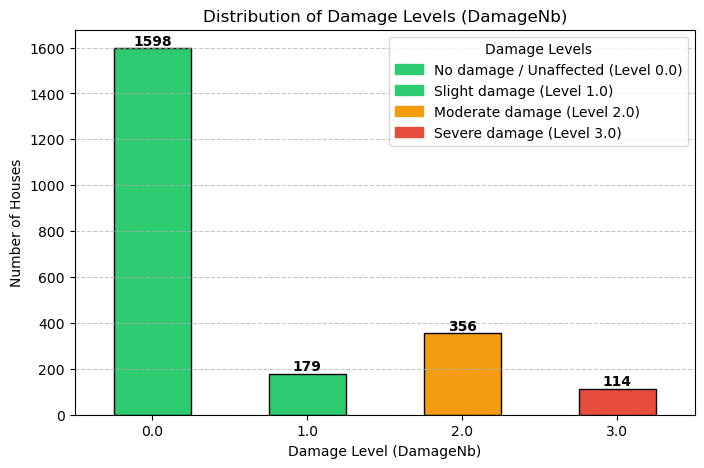

In [24]:
# Count of houses by damage level
damage_counts = placards["DamageNb"].value_counts().sort_index()
print("House counts by damage level:")


damage_level_and_colour = {
    0.0: {"label": "No damage / Unaffected", "color": "#2ecc71"},  # Green
    1.0: {"label": "Slight damage", "color": "#2ecc71"},  # Green
    2.0: {"label": "Moderate damage", "color": "#f39c12"},  # Yellow
    3.0: {"label": "Severe damage", "color": "#e74c3c"}   # Red
}

#plot the distribution of damage levels
plt.figure(figsize=(8, 5))
#use the colours from the damage_level_and_colour mapping for the bars
damage_counts.plot(kind="bar", color=[damage_level_and_colour.get(level, {"color": "#aaaaaa"})["color"] for level in damage_counts.index], edgecolor="black")
plt.title("Distribution of Damage Levels (DamageNb)")
plt.xlabel("Damage Level (DamageNb)")
plt.ylabel("Number of Houses")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

#Add the number of houses on top of each bar
for index, value in enumerate(damage_counts):
    plt.text(index, value, str(value), ha="center", va="bottom", fontweight="bold")

# Add a legend
handles = [plt.Rectangle((0, 0), 1, 1, color=info["color"]) for level, info in damage_level_and_colour.items()]
labels = [f"{info['label']} (Level {level})" for level, info in damage_level_and_colour.items()]
plt.legend(handles, labels, title="Damage Levels", loc="upper right")

#save the plot as a PNG file
plt.savefig(f"{ANALYSIS_DIR}/damage_distribution.png", dpi=300, bbox_inches="tight")

In [1]:
#Get road data for the study area using LINZ service.

#Get the building data for the study area using LINZ service.

import geopandas as gpd
import rasterio

SIMULATION_DATA_DIR = f"/data/westport/data"

ROAD_NETWORK_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/road_network.gpkg"

DEM_FILE_PATH = f"{SIMULATION_DATA_DIR}/dem/Topo.tif"
LINZ_KEY = "a06a74b6c02f4d4a81f999bd09034897"

with rasterio.open(DEM_FILE_PATH) as dem_dataset:
    dem_bounds = dem_dataset.bounds
    dem_crs = dem_dataset.crs

print(f"DEM Bounds: {dem_bounds}")
print(f"DEM CRS: {dem_crs}")

#convert dem bounds to bbox coordinates to ESPG:4167 (NZGD2000)
# from pyproj import Transformer
# transformer = Transformer.from_crs(dem_crs, "EPSG:4167", always_xy=True)
# left, bottom = transformer.transform(dem_bounds.left, dem_bounds.bottom)
# right, top = transformer.transform(dem_bounds.right, dem_bounds.top)


bbox = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top}"

# Assumes dem_bounds is already in NZTM2000 (EPSG:2193)
bbox_str = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top},EPSG:2193"

wfs_url = (
    f"https://data.linz.govt.nz/services;key={LINZ_KEY}/wfs?"
    f"service=WFS&version=2.0.0&request=GetFeature"
    f"&typeNames=layer-50796"
    f"&bbox={bbox_str}"
    f"&outputFormat=application/json"
)

roads = gpd.read_file(wfs_url)
print(f"Fetched {len(roads)} roads")

# Save the road data to a GeoPackage file
roads.to_file(ROAD_NETWORK_FILE_PATH, driver="GPKG")
print(f"Road data saved to {ROAD_NETWORK_FILE_PATH}")

DEM Bounds: BoundingBox(left=1478882.0, bottom=5367810.8, right=1490478.8, top=5379561.2)
DEM CRS: PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]]
Fetched 744 roads
Road data saved to /data/westport/data/exposure/road_network.gpkg


In [ ]:
https://data.linz.govt.nz/services;key=a06a74b6c02f4d4a81f999bd09034897/wfs/layer-50329/?service=WFS&request=GetCapabilities

In [1]:
#Get road centerline data for the study area using LINZ service.

#Get the building data for the study area using LINZ service.

import geopandas as gpd
import rasterio

SIMULATION_DATA_DIR = f"/data/westport/data"

ROAD_NETWORK_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/road_network.gpkg"
ROAD_CENTERLINES_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/road_centerlines.gpkg"

DEM_FILE_PATH = f"{SIMULATION_DATA_DIR}/dem/Topo.tif"
LINZ_KEY = "a06a74b6c02f4d4a81f999bd09034897"

with rasterio.open(DEM_FILE_PATH) as dem_dataset:
    dem_bounds = dem_dataset.bounds
    dem_crs = dem_dataset.crs

print(f"DEM Bounds: {dem_bounds}")
print(f"DEM CRS: {dem_crs}")

#convert dem bounds to bbox coordinates to ESPG:4167 (NZGD2000)
# from pyproj import Transformer
# transformer = Transformer.from_crs(dem_crs, "EPSG:4167", always_xy=True)
# left, bottom = transformer.transform(dem_bounds.left, dem_bounds.bottom)
# right, top = transformer.transform(dem_bounds.right, dem_bounds.top)


bbox = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top}"

# Assumes dem_bounds is already in NZTM2000 (EPSG:2193)
bbox_str = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top},EPSG:2193"

wfs_url = (
    f"https://data.linz.govt.nz/services;key={LINZ_KEY}/wfs?"
    f"service=WFS&version=2.0.0&request=GetFeature"
    f"&typeNames=layer-50329"
    f"&bbox={bbox_str}"
    f"&outputFormat=application/json"
)

roads = gpd.read_file(wfs_url)
print(f"Fetched {len(roads)} roads")

# Save the road data to a GeoPackage file
roads.to_file(ROAD_CENTERLINES_FILE_PATH, driver="GPKG")
print(f"Road data saved to {ROAD_CENTERLINES_FILE_PATH}")

DEM Bounds: BoundingBox(left=1478882.0, bottom=5367810.8, right=1490478.8, top=5379561.2)
DEM CRS: PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]]
Fetched 223 roads
Road data saved to /data/westport/data/exposure/road_centerlines.gpkg


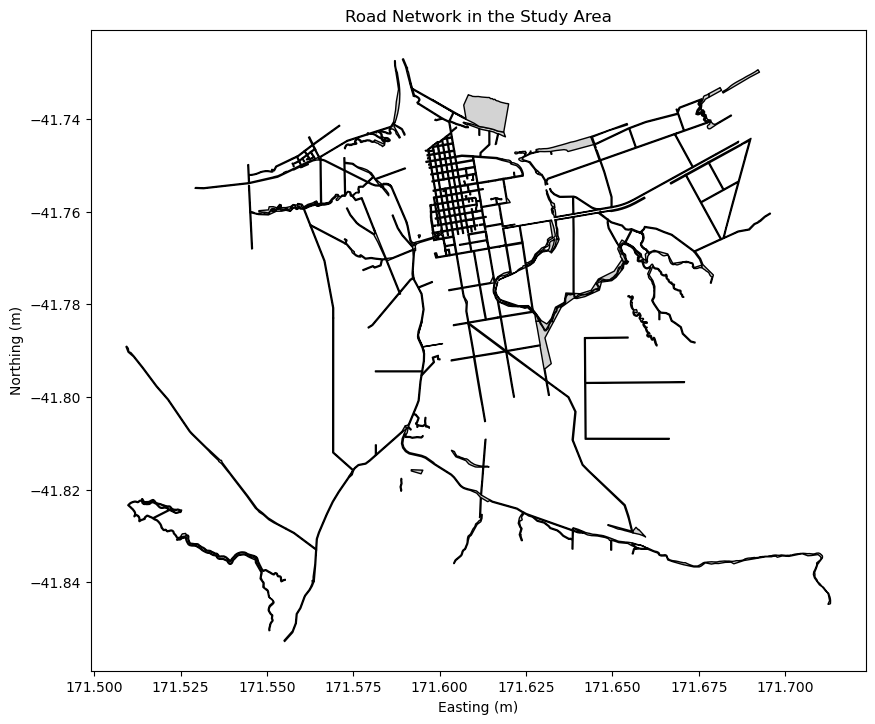

In [2]:
#Visualise the road network
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 10))
roads.plot(ax=ax, color='lightgrey', edgecolor='black')
ax.set_title("Road Network in the Study Area")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.show()